# Test residual pair similarity and cross-page clustering
Read `training_data.pt` and `residual_projection.pt`. No training or saved files.

Compare raw Magi and residual embeddings on identical held-out pairs and the original unchanged cross-page clustering algorithm. All appearances participate in clustering; only accepted GT appearances count toward metrics. These GT assignments remain noisy supervision.


## 1. Load the saved residual model
Verify the exact dataset hash and model configuration. The selected checkpoint can validly be epoch 0 if training never improved validation balanced accuracy.


In [1]:
import torch
from torch import nn
import torch.nn.functional as F
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/charSimResidual')
DATA_FILE = ROOT / 'training_data.pt'
MODEL_FILE = ROOT / 'residual_projection.pt'
BATCH_SIZE = 512
HARD_COSINE = 0.8
assert torch.cuda.is_available(), 'Use Godfather with CUDA-enabled PyTorch.'
device = torch.device('cuda:0')
data = torch.load(DATA_FILE, map_location='cpu', weights_only=True)
saved = torch.load(MODEL_FILE, map_location='cpu', weights_only=True)
assert data['version'] == saved['version'] == 3, 'Rebuild data and train the redesigned model first.'
with DATA_FILE.open('rb') as file:
    assert hashlib.file_digest(file, 'sha256').hexdigest() == saved['data_hash'], 'Dataset changed since training.'
assert not (set(data['splits']['train']) & set(data['splits']['validation']) or
            set(data['splits']['train']) & set(data['splits']['test']) or
            set(data['splits']['validation']) & set(data['splits']['test']))
class ResidualCharacterProjection(nn.Module):
    def __init__(self, embedding_dim=768, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, embedding_dim)
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        x = F.normalize(x, dim=-1)
        delta = self.fc2(F.relu(self.fc1(x)))
        return F.normalize(x + delta, dim=-1)
model = ResidualCharacterProjection(**saved['model_config']).to(device)
model.load_state_dict(saved['model_state'])
model.eval()
print('Checkpoint epoch:', saved['epoch'], '| model settings:', saved['model_config'])


Checkpoint epoch: 9 | model settings: {'embedding_dim': 768, 'hidden_dim': 64}


## 2. Project each appearance once
GPU runs the MLP in batches. Retain raw normalized vectors and projected vectors for both pair scoring and clustering. Preserve the original appearance row indices.


In [2]:
@torch.inference_mode()
def make_features():
    features = {'Raw Magi': {}, 'Residual projection': {}}
    for i in data['splits']['validation'] + data['splits']['test']:
        embeddings = data['sequences'][i]['embeddings']
        features['Raw Magi'][i] = F.normalize(embeddings, dim=-1).numpy()
        batches = [model(x.to(device)).cpu() for x in embeddings.split(BATCH_SIZE) if len(x)]
        features['Residual projection'][i] = torch.cat(batches).numpy() if batches else np.empty((0, 768))
    return features

features = make_features()

def pair_scores(split, vectors):
    rows = data['pairs'][split].tolist()
    scores = np.array([np.dot(vectors[i][a], vectors[i][b]) for i, a, b, _ in rows]).clip(-1, 1)
    labels = np.array([y for _, _, _, y in rows])
    cross = np.array([int(data['sequences'][i]['page'][a]) != int(data['sequences'][i]['page'][b])
                      for i, a, b, _ in rows])
    assert set(labels.tolist()) == {0, 1}
    return scores, labels, cross

def metrics(scores, labels, threshold):
    predicted = scores >= threshold
    positive, negative = labels == 1, labels == 0
    same = float(predicted[positive].mean()) if positive.any() else float('nan')
    different = float((~predicted[negative]).mean()) if negative.any() else float('nan')
    return dict(balanced_accuracy=(same + different) / 2,
                same_recall=same, different_recall=different,
                accuracy=float((predicted == labels).mean()) if len(labels) else float('nan'))

def choose_threshold(scores, labels):
    # Check all distinct score boundaries efficiently, including predicting nobody SAME.
    assert set(labels.tolist()) == {0, 1}
    order = np.argsort(-scores, kind='stable')
    values, targets = scores[order], labels[order]
    ends = np.r_[np.where(values[:-1] != values[1:])[0], len(values)-1]
    tp = np.cumsum(targets)[ends]
    fp = (ends + 1) - tp
    balanced = (tp / targets.sum() + 1 - fp / (len(targets)-targets.sum())) / 2
    best = int(np.argmax(balanced))
    return float(values[ends[best]]) if balanced[best] > 0.5 else float(np.nextafter(float(values[0]), np.inf))


## 3. Pair classification
Calibrate each method on validation pairs, using exact score boundaries. The test pairs never choose thresholds. Report cross-page and same-page results separately. A missing class produces NaN balanced accuracy, not a misleading score.

The hard-negative report shows rejection of test DIFFERENT pairs with raw cosine ≥0.8. It is a diagnostic subset, not a replacement for representative test evaluation.


,method,subset,pairs,threshold,balanced_accuracy,same_recall,different_recall,accuracy
0,Raw Magi,all,1200,0.6732,0.7426,0.6865,0.7988,0.7642
1,Raw Magi,cross_page,828,0.6732,0.7598,0.7056,0.8141,0.7838
2,Raw Magi,same_page,372,0.6732,0.7072,0.6547,0.7597,0.7204
3,Residual projection,all,1200,0.6993,0.7424,0.6703,0.8145,0.7700
4,Residual projection,cross_page,828,0.6993,0.7561,0.6797,0.8325,0.7899
5,Residual projection,same_page,372,0.6993,0.7115,0.6547,0.7682,0.7258


Cross-page | SAME: 231 | DIFFERENT: 597
Same-page | SAME: 139 | DIFFERENT: 233
Hard test negatives: 76
Raw Magi | hard-negative rejection: 0.0
Residual projection | hard-negative rejection: 0.0


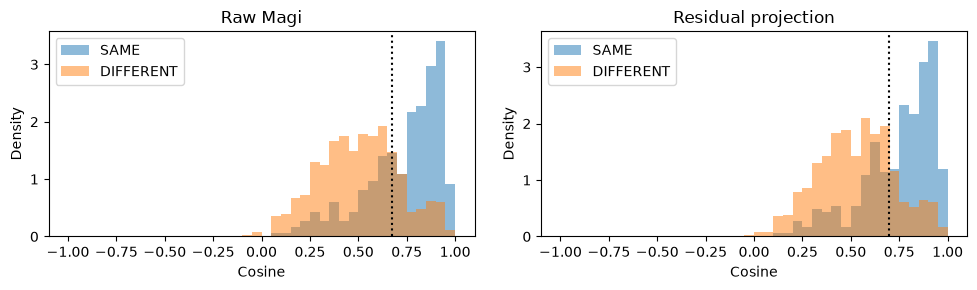

In [3]:
pair_thresholds, results, test_scores = {}, [], {}
for name, vectors in features.items():
    val_scores, val_labels, _ = pair_scores('validation', vectors)
    threshold = choose_threshold(val_scores, val_labels)
    pair_thresholds[name] = threshold
    scores, labels, cross = pair_scores('test', vectors)
    test_scores[name] = scores
    for subset, mask in [('all', np.ones(len(labels), dtype=bool)),
                         ('cross_page', cross), ('same_page', ~cross)]:
        results.append(dict(method=name, subset=subset, pairs=int(mask.sum()), threshold=threshold,
                            **metrics(scores[mask], labels[mask], threshold)))
display(pd.DataFrame(results).round(4))
for cross_page in [True, False]:
    mask = cross if cross_page else ~cross
    print('Cross-page' if cross_page else 'Same-page', '| SAME:', int(((labels == 1) & mask).sum()),
          '| DIFFERENT:', int(((labels == 0) & mask).sum()))

hard = (labels == 0) & (test_scores['Raw Magi'] >= HARD_COSINE)
print('Hard test negatives:', int(hard.sum()))
if hard.any():
    for name in features:
        rejected = (test_scores[name][hard] < pair_thresholds[name]).mean()
        print(name, '| hard-negative rejection:', round(float(rejected), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (name, scores) in zip(axes, test_scores.items()):
    for y, label in [(1, 'SAME'), (0, 'DIFFERENT')]:
        ax.hist(scores[labels == y], bins=np.linspace(-1, 1, 41), density=True, alpha=0.5, label=label)
    ax.axvline(pair_thresholds[name], color='black', linestyle=':')
    ax.set(title=name, xlabel='Cosine', ylabel='Density'); ax.legend()
plt.tight_layout(); plt.show()


## 4. Run the actual clustering algorithm
Keep Magi's page-local clusters fixed. Process pages in order; compare each local cluster with existing entities by strongest member-to-member cosine. Assign strongest candidates first, allowing at most one local cluster per existing entity on each page. Create new entities for unmatched clusters.

This mirrors pipeline1. No GT identities enter clustering. Local clustering errors cannot be repaired by this cross-page projection alone. All appearances, including unlabeled ones, participate.


In [4]:
def cluster_entities(sequence, vectors, threshold):
    assignments = np.full(len(vectors), -1, dtype=int)
    entities = []
    pages = sequence['page'].numpy()
    labels = sequence['cluster'].numpy()
    characters = sequence['character'].numpy()
    for page in range(len(sequence['page_files'])):
        groups = {}
        for row in np.where(pages == page)[0]:
            key = int(labels[row]) if labels[row] >= 0 else -int(characters[row])-1
            groups.setdefault(key, []).append(int(row))
        candidates = []
        for key, members in groups.items():
            for entity, existing in enumerate(entities):
                score = float((vectors[members] @ vectors[existing].T).max())
                if score >= threshold:
                    candidates.append((score, key, entity))
        candidates.sort(key=lambda item: item[0], reverse=True)
        accepted, used_entities = {}, set()
        for score, key, entity in candidates:
            if key not in accepted and entity not in used_entities:
                accepted[key] = entity
                used_entities.add(entity)
        for key, members in groups.items():
            if key in accepted:
                entity = accepted[key]
            else:
                entity = len(entities)
                entities.append([])
            entities[entity].extend(members)
            assignments[members] = entity
    assert np.all(assignments >= 0)
    return assignments

def clustering_metrics(split, vectors, threshold):
    predicted = {i: cluster_entities(data['sequences'][i], vectors[i], threshold)
                 for i in data['splits'][split]}
    truth, same_entity = [], []
    for i, a, b, y in data['pairs'][split].tolist():
        s = data['sequences'][i]
        if s['page'][a] != s['page'][b]:
            truth.append(y)
            same_entity.append(int(predicted[i][a] == predicted[i][b]))
    assert truth, 'No labeled cross-page pairs for clustering evaluation.'
    result = metrics(np.array(same_entity), np.array(truth), 0.5)
    return dict(cross_page_pairs=len(truth), **result)


## 5. Validation-selected clustering thresholds and test results
Tune clustering thresholds independently from pair thresholds, because best-member aggregation changes behavior. Search a simple 0–1 grid (step 0.02) on validation sequences, then evaluate once on test sequences.

The reported clustering metric compares SAME/DIFFERENT identities implied by the final E clusters for labeled cross-page pairs. Low DIFFERENT recall indicates erroneous identity merges; low SAME recall indicates splits. Raw/projected methods use identical detections and local clusters. No automatic improvement claim is made when results are worse.


In [5]:
cluster_results = []
for name, vectors in features.items():
    trials = []
    for threshold in np.linspace(0, 1, 51):
        result = clustering_metrics('validation', vectors, float(threshold))
        if np.isfinite(result['balanced_accuracy']):
            trials.append((result['balanced_accuracy'], float(threshold)))
    assert trials, 'Validation clustering needs both cross-page pair classes.'
    _, threshold = max(trials, key=lambda item: item[0])
    cluster_results.append(dict(method=name, threshold=threshold,
        **clustering_metrics('test', vectors, threshold)))
display(pd.DataFrame(cluster_results).round(4))
print('No files saved. Judge pair and clustering results separately.')


,method,threshold,cross_page_pairs,balanced_accuracy,same_recall,different_recall,accuracy
0,Raw Magi,0.78,828,0.7142,0.5541,0.8744,0.7850
1,Residual projection,0.80,828,0.7162,0.5714,0.8610,0.7802


No files saved. Judge pair and clustering results separately.
